**AQI Prediction Using Random Forest Regression**

**OBJECTIVE:**

The objective is to predict AQI from pollutant concentrations using a machine-learning algorithm.



**IMPORT LIBRARIES**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Air_quality_data.csv to Air_quality_data.csv


**LOAD DATA SET**

In [ ]:
import pandas as pd

df = pd.read_csv(next(iter(uploaded)))

df.head()

,City,Datetime,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,AQI_Bucket
0,Delhi,2015-01-01,153.3,241.7,182.9,33.0,81.3,38.5,1.87,64.5,83.6,325.8,Very Poor
1,Mumbai,2015-01-01,70.5,312.7,195.0,42.0,122.5,31.5,7.22,83.8,108.0,262.7,Poor
2,Chennai,2015-01-01,174.1,275.4,56.2,68.8,230.9,28.5,8.56,60.8,43.9,341.8,Very Poor
3,Kolkata,2015-01-01,477.2,543.9,14.1,76.4,225.9,45.6,2.41,42.1,171.1,206.3,Poor
4,Bangalore,2015-01-01,171.6,117.7,123.3,12.4,61.9,49.7,1.26,79.7,164.3,339.8,Very Poor


In [ ]:
df.isnull().sum()

,0
City,0
Datetime,0
PM2.5,0
PM10,0
NO,0
NO2,0
NOx,0
NH3,0
CO,0
SO2,0


In [ ]:
df.shape

(18265, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18265 entries, 0 to 18264
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        18265 non-null  object 
 1   Datetime    18265 non-null  object 
 2   PM2.5       18265 non-null  float64
 3   PM10        18265 non-null  float64
 4   NO          18265 non-null  float64
 5   NO2         18265 non-null  float64
 6   NOx         18265 non-null  float64
 7   NH3         18265 non-null  float64
 8   CO          18265 non-null  float64
 9   SO2         18265 non-null  float64
 10  O3          18265 non-null  float64
 11  AQI         18265 non-null  float64
 12  AQI_Bucket  18265 non-null  object 
dtypes: float64(10), object(3)
memory usage: 1.8+ MB


**DATA PREPARATION**

In [ ]:
# Select input features
X = df[['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3']]

# Select target variable
y = df['AQI']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (18265, 9)
Target shape: (18265,)


**TRAIN-TEST SPLIT**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (14612, 9)
Testing data: (3653, 9)


**TRAIN RANDOM FOREST MODEL**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


**MODEL PREDICTION**

In [ ]:
# Predict AQI using Random Forest
rf_pred = rf_model.predict(X_test)

print("First 10 predicted AQI values:")
print(rf_pred[:10])

First 10 predicted AQI values:
[262.278 259.094 361.183 485.514 237.648 419.018 473.873 341.563 473.682
 185.134]


**MODEL EVALUATION**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("--------------------")
print("Mean Absolute Error:", rf_mae)
print("Mean Squared Error:", rf_mse)
print("R² Score:", rf_r2)

Random Forest Results
--------------------
Mean Absolute Error: 1.038259238981661
Mean Squared Error: 40.41053656528885
R² Score: 0.9969663475851024


**Actual vs Predicted graph**

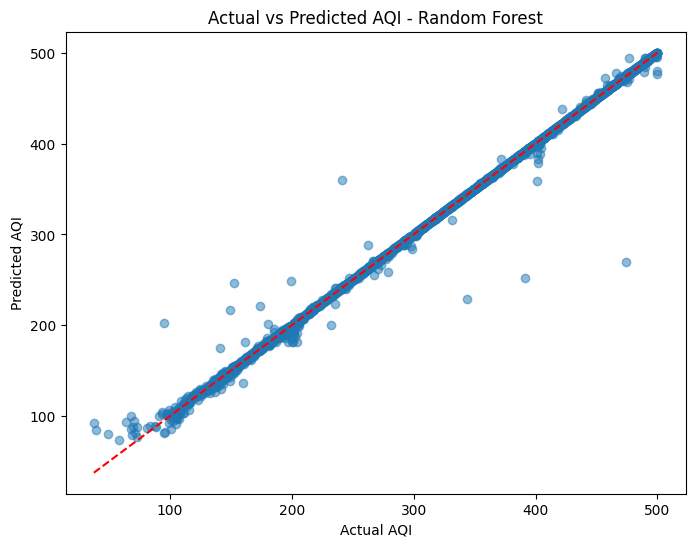

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.5)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI - Random Forest")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.show()

**Feature Importance graph**

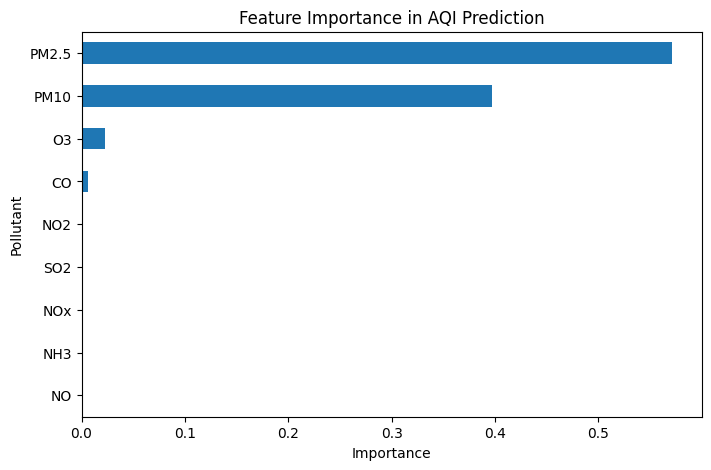

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 5))

importance.plot(kind='barh')

plt.xlabel("Importance")
plt.ylabel("Pollutant")
plt.title("Feature Importance in AQI Prediction")

plt.show()

**NEW AQI PREDICTION**

In [ ]:
# AQI Prediction for New Input

new_data = pd.DataFrame([{
    'PM2.5': float(input("Enter PM2.5 value: ")),
    'PM10': float(input("Enter PM10 value: ")),
    'NO': float(input("Enter NO value: ")),
    'NO2': float(input("Enter NO2 value: ")),
    'NOx': float(input("Enter NOx value: ")),
    'NH3': float(input("Enter NH3 value: ")),
    'CO': float(input("Enter CO value: ")),
    'SO2': float(input("Enter SO2 value: ")),
    'O3': float(input("Enter O3 value: "))
}])

predicted_aqi = rf_model.predict(new_data)[0]

print("\nPredicted AQI:", round(predicted_aqi, 2))

Enter PM2.5 value: 153.3
Enter PM10 value: 241.7
Enter NO value: 182.9
Enter NO2 value: 33.0
Enter NOx value: 81.3
Enter NH3 value: 38.5
Enter CO value: 1.87
Enter SO2 value: 64.5
Enter O3 value: 83.6

Predicted AQI: 325.78


**Conclusion**



The Random Forest Regression model was successfully implemented using Python and Scikit-learn to predict Air Quality Index from pollutant concentrations. The model was trained, evaluated, and used to predict AQI for new input values. The results demonstrate that machine learning can be used to estimate AQI based on air pollutant measurements.